# CV Day 1 · ⑦ 고정 필터와 CNN의 학습된 필터 비교

**Module 2. 이미지 처리와 특징 추출 · 실습 A+B+C · 50분 · CPU · 전원 필수 실습**

이 실습은 ⑤교시의 Sobel과 ⑥교시의 CNN을 연결합니다. **완성된 코드를 실행 → 결과 확인 → ★ 파라미터 변경 → 다시 실행 → 이유 설명** 순서로 진행합니다.

| 구간 | 시간 | 확인할 결과 |
|---|---:|---|
| 0. 준비 | 5분 | 공통 이미지, 사전학습 SqueezeNet 1.1, NCHW |
| A. 고정 필터 vs 학습된 필터 | 15분 | Sobel·초기 CNN Feature Map, 채널 바꾸기 |
| B. Conv 출력 Shape | 12분 | Kernel·Stride·Padding, 파라미터 수 |
| C. 계층별 Feature Map | 13분 | 초기·중간·깊은 계층, 채널 바꾸기 |
| E. 종합 비교 | 5분 | 전체 결과 및 개념 해석 |

**중요:** SqueezeNet 1.1은 *ImageNet으로 사전학습한 가중치*를 사용합니다. 모델을 새로 학습하지 않습니다. 가중치 파일이 없으면 최초 한 번 다운로드가 필요합니다. 오프라인 교실에서는 강사가 `assets/`에 공식 가중치 파일을 배치해야 합니다. **임의로 초기화된 필터를 학습된 필터라고 해석하지 않습니다.**

## 0. 준비 — 이미지·라이브러리·모델 확인 (5분)

①교시 복습: NumPy RGB 이미지는 `(H, W, C)`, PyTorch의 CNN 입력은 `(N, C, H, W)`입니다. ③·⑤교시에서 사용한 **같은** `assets/color_sample.png`를 사용합니다.

**가중치 준비(강사 사전 점검)**

- 공식 파일: `squeezenet1_1-b8a52dc0.pth` (약 4.7 MB)
- 오프라인 환경: `module2_cv_nlp/assets/squeezenet1_1-b8a52dc0.pth`에 미리 저장합니다.
- 온라인 환경: 로컬 파일이 없으면 TorchVision이 공식 파일을 최초 1회 내려받아 캐시에 저장합니다.
- 이미 설치된 PyTorch 환경을 유지하세요. CUDA 드라이버나 GPU는 이 날 필요하지 않습니다.

다운로드 주소: https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth

**아래 코드의 모델 로딩이 실패하면 다음 셀로 넘어가지 말고 가중치 파일이나 네트워크를 확인하세요.**

PyTorch: 2.15.0
TorchVision weights: IMAGENET1K_V1
PIL size (W, H): (512, 512)
NumPy RGB shape (H, W, C): (512, 512, 3)
dtype: uint8


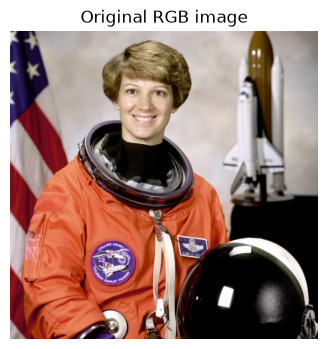

In [1]:
from pathlib import Path
import hashlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision.models import squeezenet1_1, SqueezeNet1_1_Weights
from torchvision.transforms import functional as TF

# 공통 이미지: Notebook을 module2_cv_nlp 폴더에서 열든, 상위 폴더에서 열든 사용 가능
candidates = [Path.cwd(), Path.cwd() / 'module2_cv_nlp', Path.cwd().parent / 'module2_cv_nlp']
PROJECT = next((p for p in candidates if (p / 'assets' / 'color_sample.png').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('assets/color_sample.png가 없습니다. Notebook과 assets 폴더 위치를 확인하세요.')

image_path = PROJECT / 'assets' / 'color_sample.png'
pil_image = Image.open(image_path).convert('RGB')
original_rgb = np.array(pil_image)

# 공용 학습 환경에서 CPU 과도한 스레드 사용을 피함
if torch.get_num_threads() > 4:
    torch.set_num_threads(4)

print('PyTorch:', torch.__version__)
print('TorchVision weights:', SqueezeNet1_1_Weights.DEFAULT.name)
print('PIL size (W, H):', pil_image.size)
print('NumPy RGB shape (H, W, C):', original_rgb.shape)
print('dtype:', original_rgb.dtype)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(original_rgb)
ax.set_title('Original RGB image')
ax.axis('off')
plt.show()

**중간 결과 확인 ①:** 이미지가 보이고, NumPy Shape가 `(512, 512, 3)`인지 확인합니다. 이 이미지는 ③·⑤교시에서 사용한 공통 이미지입니다.

Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /Users/jian/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100.0%


공식 사전학습 가중치 다운로드 및 로드 완료
공식 전처리: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
CNN Input (NCHW): (1, 3, 224, 224)
학습 가능한 파라미터: 1,235,496
Sobel용 공통 영역 (HWC): (224, 224, 3)


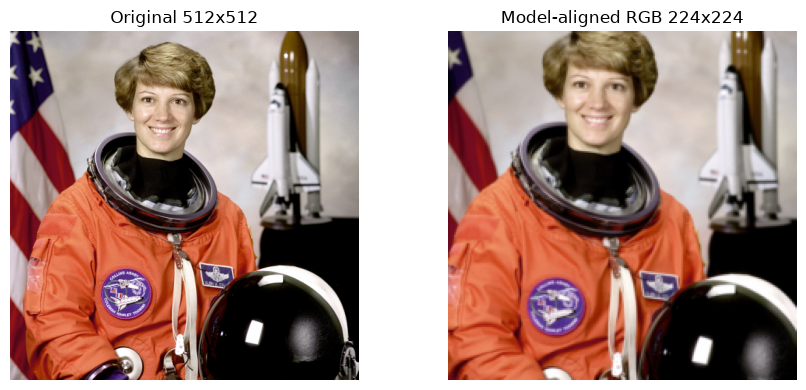

In [2]:
# 모델 가중치 출처: TorchVision SqueezeNet 1.1 / ImageNet-1K
weights = SqueezeNet1_1_Weights.DEFAULT
preprocess = weights.transforms()
weight_filename = 'squeezenet1_1-b8a52dc0.pth'
local_checkpoint = PROJECT / 'assets' / weight_filename
cached_checkpoint = Path(torch.hub.get_dir()) / 'checkpoints' / weight_filename

# ① 로컬/캐시 가중치가 있으면 오프라인 로드
# ② 둘 다 없으면 공식 TorchVision 다운로드 시도
available_checkpoint = next((p for p in [local_checkpoint, cached_checkpoint] if p.is_file()), None)

if available_checkpoint is not None:
    # 파일명이 포함하는 SHA256 접두어를 확인해 잘못된 파일 사용 방지
    digest = hashlib.sha256(available_checkpoint.read_bytes()).hexdigest()
    if not digest.startswith('b8a52dc0'):
        raise ValueError(f'가중치 파일 해시가 공식 파일과 다릅니다: {available_checkpoint}')
    model = squeezenet1_1(weights=None)
    state_dict = torch.load(available_checkpoint, map_location='cpu', weights_only=True)
    model.load_state_dict(state_dict, strict=True)
    print('사전학습 가중치 로드 (로컬/캐시):', available_checkpoint)
else:
    try:
        model = squeezenet1_1(weights=weights)
        print('공식 사전학습 가중치 다운로드 및 로드 완료')
    except Exception as exc:
        raise RuntimeError(
            '공식 사전학습 가중치를 가져오지 못했습니다. 수업 전 위 URL에서 '
            f'{weight_filename}를 내려받아 {PROJECT / "assets"}에 넣으세요. '
            '무작위 초기화 모델로 실습을 계속하지 않습니다.'
        ) from exc

model = model.cpu().eval()

# 공식 전처리: Resize(shorter side=256) → Center Crop(224) → [0,1] → mean/std 정규화
input_tensor = preprocess(pil_image).unsqueeze(0)
assert input_tensor.shape == (1, 3, 224, 224)
print('공식 전처리:', preprocess)
print('CNN Input (NCHW):', tuple(input_tensor.shape))
print('학습 가능한 파라미터:', f'{sum(p.numel() for p in model.parameters()):,}')

# Sobel은 CNN과 동일한 공간 영역을 사용하되 원본 RGB의 uint8 밝기값으로 계산
aligned_pil = TF.center_crop(
    TF.resize(pil_image, preprocess.resize_size, interpolation=preprocess.interpolation),
    preprocess.crop_size,
)
aligned_rgb = np.array(aligned_pil)
aligned_gray = cv2.cvtColor(aligned_rgb, cv2.COLOR_RGB2GRAY)
assert aligned_rgb.shape == (224, 224, 3)
print('Sobel용 공통 영역 (HWC):', aligned_rgb.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(original_rgb); axes[0].set_title('Original 512x512')
axes[1].imshow(aligned_rgb); axes[1].set_title('Model-aligned RGB 224x224')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

**중간 결과 확인 ②:** CNN 입력은 `(1, 3, 224, 224)`입니다. Sobel은 *동일하게 잘라낸 영역*의 원래 밝기값을 사용합니다. CNN 입력은 사전학습 모델의 평균·표준편차로 정규화되며, 이 두 출력의 수치 단위는 서로 다릅니다.

## A-1. Sobel 고정 필터와 CNN 초기 Feature Map 비교 (약 10분)

⑤교시 복습: Sobel X는 좌우 밝기 변화에 반응하여 **세로 경계**를, Sobel Y는 상하 밝기 변화에 반응하여 **가로 경계**를 강조합니다. Sobel의 Kernel 가중치는 고정되어 있습니다.

CNN의 초기 출력은 **학습된 가중치**를 이용해 생성됩니다. SqueezeNet 1.1의 `features[1]`은 첫 Conv의 ReLU 출력입니다. 아래 코드는 중간 결과를 Hook으로 얻습니다.

Sobel X min/max: -856.0 841.0
Sobel Y min/max: -814.0 939.0
CNN early Feature Map NCHW: (1, 64, 111, 111)
CNN 채널 수: 64


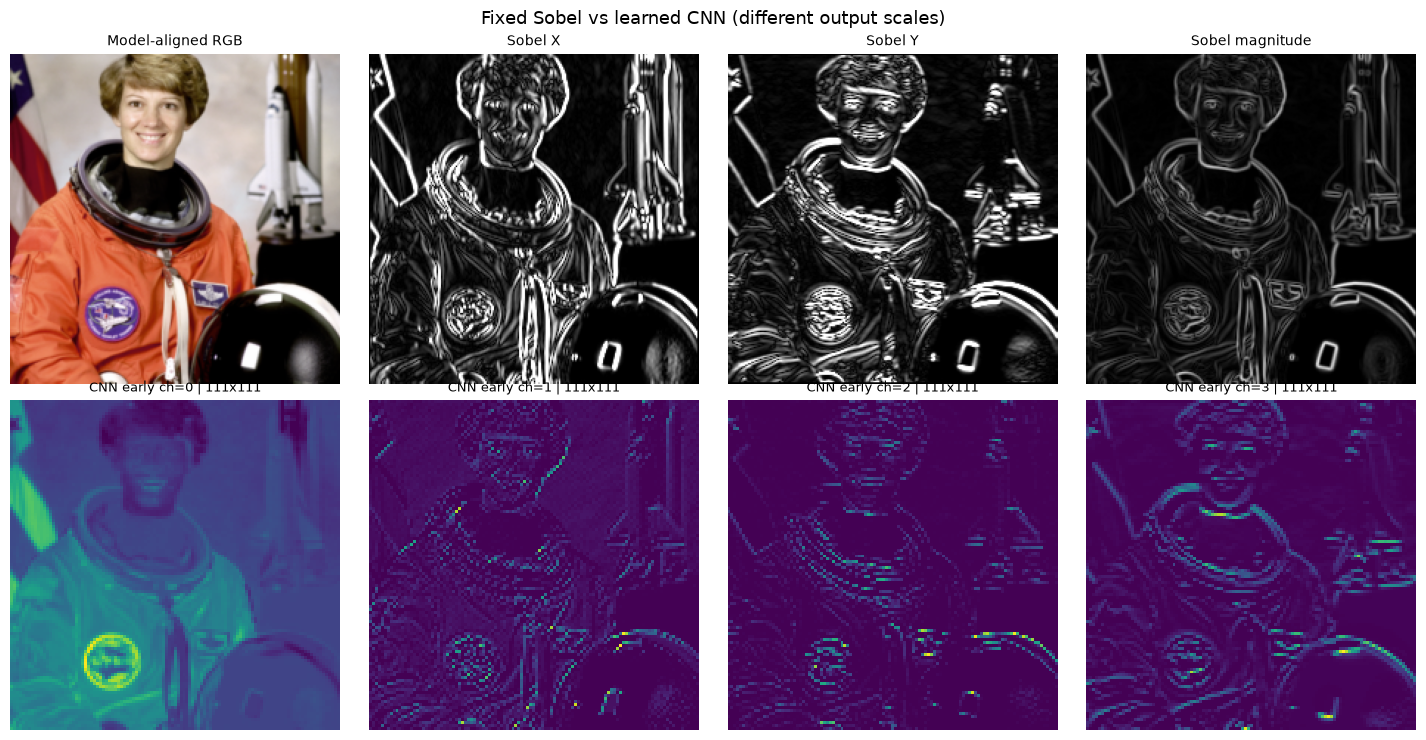

In [3]:
# 고정 Sobel: 미분 결과는 음수가 가능하므로 실수로 계산
sobel_x = cv2.Sobel(aligned_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(aligned_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = np.hypot(sobel_x, sobel_y)

# 아래 두 결과는 보기 위한 시각화값. 원래 Gradient의 부호/절대 크기를 보존하지는 않음
sobel_x_view = cv2.convertScaleAbs(sobel_x)
sobel_y_view = cv2.convertScaleAbs(sobel_y)
sobel_mag_view = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# CNN 초기 Feature Map 저장. Hook은 중복 등록되지 않도록 반드시 제거함
early_holder = {}
def capture_early(module, inputs, output):
    early_holder['map'] = output.detach().cpu().clone()

handle = model.features[1].register_forward_hook(capture_early)
try:
    with torch.inference_mode():
        _ = model(input_tensor)
finally:
    handle.remove()

early_map = early_holder['map']
assert tuple(early_map.shape) == (1, 64, 111, 111)
print('Sobel X min/max:', round(sobel_x.min(), 1), round(sobel_x.max(), 1))
print('Sobel Y min/max:', round(sobel_y.min(), 1), round(sobel_y.max(), 1))
print('CNN early Feature Map NCHW:', tuple(early_map.shape))
print('CNN 채널 수:', early_map.shape[1])

# 매 채널별로 표시 범위를 따로 설정. 채널 간 '화면 밝기'는 크기 비교 불가
def show_feature(ax, tensor_nchw, channel, label='CNN'):
    mat = tensor_nchw[0, channel].numpy()
    vmin, vmax = float(mat.min()), float(mat.max())
    if vmax == vmin:
        vmax = vmin + 1e-6
    ax.imshow(mat, cmap='viridis', vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(f'{label} ch={channel} | {mat.shape[0]}x{mat.shape[1]}', fontsize=9)
    ax.axis('off')
    return (vmin, float(mat.max()), float(mat.mean()))

fig, axes = plt.subplots(2, 4, figsize=(14.5, 7.5))
for ax, img, title in zip(axes[0],
                          [aligned_rgb, sobel_x_view, sobel_y_view, sobel_mag_view],
                          ['Model-aligned RGB', 'Sobel X', 'Sobel Y', 'Sobel magnitude']):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(img)
    ax.set_title(title, fontsize=10); ax.axis('off')
for ax, ch in zip(axes[1], [0, 1, 2, 3]):
    show_feature(ax, early_map, ch, 'CNN early')
fig.suptitle('Fixed Sobel vs learned CNN (different output scales)', fontsize=13)
plt.tight_layout(); plt.show()

**중간 결과 확인 ③**

- Sobel은 설계된 방향별 Gradient를 계산합니다. CNN 초기 계층은 64개의 Feature Map을 생성합니다.
- Feature Map은 **픽셀값이 아니라 필터 반응(활성화값)**입니다. Sobel의 픽셀 밝기와 직접 비교해 크고 작음을 판단하지 않습니다.
- 채널마다 색상이 비슷해도 값의 범위를 개별 조절했기 때문에 활성화값이 동일하다는 의미는 아닙니다.

**관찰 질문 A-1:** CNN의 네 채널이 모두 같은 경계만 강조하나요? Sobel과 다른 패턴을 보이는 채널을 찾아보세요.

## A-2. ★ CNN에서 관찰할 채널 변경 (약 5분)

**★ 변경할 값:** `channel_indices = [0, 1, 2, 3]` → `[4, 5, 6, 7]`. **동일한 이미지와 동일한 모델**을 유지하며 채널만 변경합니다.

채널  0: 원래 활성화 최소=0.000, 최대=5.238, 평균=1.474
채널  1: 원래 활성화 최소=0.000, 최대=2.750, 평균=0.116
채널  2: 원래 활성화 최소=0.000, 최대=5.716, 평균=0.138
채널  3: 원래 활성화 최소=0.000, 최대=12.714, 평균=0.515


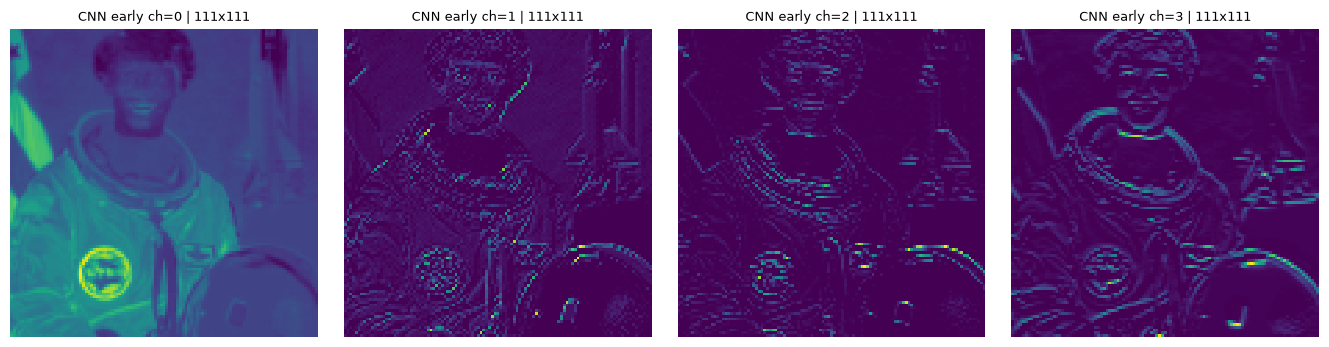

In [4]:
# ★ 변경할 값: [0, 1, 2, 3] → [4, 5, 6, 7]
channel_indices = [0, 1, 2, 3]
assert len(channel_indices) == 4
assert all(0 <= ch < early_map.shape[1] for ch in channel_indices)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.4))
for ax, ch in zip(axes, channel_indices):
    vmin, vmax, mean = show_feature(ax, early_map, ch, 'CNN early')
    print(f'채널 {ch:2d}: 원래 활성화 최소={vmin:.3f}, 최대={vmax:.3f}, 평균={mean:.3f}')
plt.tight_layout(); plt.show()

**관찰 질문 A-2:** 채널만 바꾸어도 반응하는 위치와 패턴이 달라지나요? **하나의 채널에 특정 사물의 의미를 단정하지는 않습니다.**

## B-1. Kernel·Stride·Padding → 출력 Tensor Shape (약 7분)

⑥교시 복습: 일반적인 2D Convolution에서 Dilation=1일 때, `H_out = floor((H_in + 2P - K)/S) + 1`입니다.

여기서는 **사전학습 모델의 가중치를 변경하지 않고**, 별도의 초기화된 `Conv2d`로 구조와 Shape만 확인합니다. 이 부분은 *학습된 특징을 해석하는 실습이 아닙니다.*

case    K   S   P  output NCHW         params
A       3   1   1  (1, 8, 32, 32)         224
B       3   1   0  (1, 8, 30, 30)         224
C       3   2   1  (1, 8, 16, 16)         224


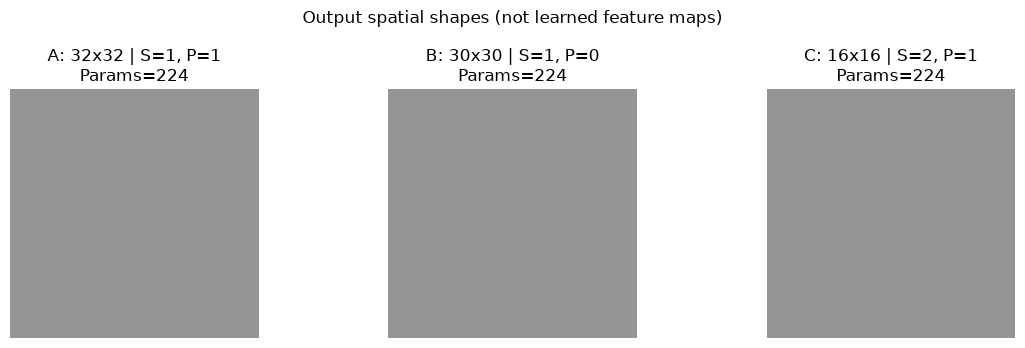

In [5]:
# 고정 입력: N=1, C=3, H=W=32; 출력 채널은 8개로 고정
shape_input = torch.zeros((1, 3, 32, 32))

cases = [
    ('A', 3, 1, 1),
    ('B', 3, 1, 0),
    ('C', 3, 2, 1),
]

shape_rows = []
print(f'{"case":<5} {"K":>3} {"S":>3} {"P":>3}  {"output NCHW":<19} {"params":>6}')
for label, k, s, p in cases:
    conv = nn.Conv2d(in_channels=3, out_channels=8,
                     kernel_size=k, stride=s, padding=p, bias=True)
    with torch.inference_mode():
        y = conv(shape_input)
    expected_hw = ((32 + 2 * p - k) // s) + 1
    actual_shape = tuple(y.shape)
    assert actual_shape == (1, 8, expected_hw, expected_hw)
    n_params = sum(t.numel() for t in conv.parameters())
    assert n_params == (3 * k * k + 1) * 8
    shape_rows.append((label, k, s, p, actual_shape, n_params))
    print(f'{label:<5} {k:>3} {s:>3} {p:>3}  {str(actual_shape):<19} {n_params:>6}')

# 시각 비교: 출력 공간 크기를 정사각형으로 표시
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, row in zip(axes, shape_rows):
    label, k, s, p, out_shape, params = row
    h, w = out_shape[2:]
    ax.imshow(np.ones((h, w)), cmap='Greys', vmin=0, vmax=2, interpolation='nearest')
    ax.set_title(f'{label}: {h}x{w} | S={s}, P={p}\nParams={params}')
    ax.axis('off')
fig.suptitle('Output spatial shapes (not learned feature maps)', fontsize=12)
plt.tight_layout(); plt.show()

**중간 결과 확인 ④:** `(1,8,32,32)`, `(1,8,30,30)`, `(1,8,16,16)`이 나와야 합니다. K=3, 입력/출력 채널이 같으면 **Stride·Padding을 바꿔도 파라미터 수는 224개로 동일**합니다.

## B-2. ★ Kernel Size 1·3·5 비교 (약 5분)

Stride=1, Padding=0으로 고정하고 Kernel만 변경합니다. 출력 크기와 파라미터 수가 **서로 다른 이유**를 확인해 보세요.

**★ 변경할 값:** 기본 `[1,3,5]`를 실행한 뒤 `[1,3,7]`로 변경하여 재실행합니다.

In [6]:
# ★ 변경할 값: [1, 3, 5] → [1, 3, 7]
kernel_sizes = [1, 3, 5]

print(f'{"Kernel":>6}  {"Output shape":<19} {"Parameters":>10}')
for k in kernel_sizes:
    conv = nn.Conv2d(3, 8, kernel_size=k, stride=1, padding=0)
    with torch.inference_mode():
        y = conv(shape_input)
    n_params = sum(t.numel() for t in conv.parameters())
    h_expected = 32 - k + 1
    assert tuple(y.shape) == (1, 8, h_expected, h_expected)
    print(f'{k:>6}  {str(tuple(y.shape)):<19} {n_params:>10}')

Kernel  Output shape        Parameters
     1  (1, 8, 32, 32)              32
     3  (1, 8, 30, 30)             224
     5  (1, 8, 28, 28)             608


**관찰 질문 B:** Kernel Size를 크게 하면 공간 출력은 어떻게 변하나요? Stride·Padding을 변경할 때와 달리 **필터 가중치 개수**는 어떻게 변하나요?

## C-1. 초기·중간·깊은 계층의 Feature Map 확인 (약 8분)

이번에는 **실제로 사전학습한 SqueezeNet 1.1**의 세 지점을 관찰합니다.

| 위치 | 선택한 출력 | 기대 Shape (NCHW) |
|---|---|---|
| 초기 | `features[1]`: 첫 Conv 뒤 ReLU | `(1,64,111,111)` |
| 중간 | `features[6]`: 중간 Fire 블록 | `(1,256,27,27)` |
| 깊은 계층 | `features[12]`: 마지막 Fire 블록 | `(1,512,13,13)` |

**왜 달라질까요?** 이 모델은 여러 계층에서 Pooling 등으로 공간 해상도를 줄이고, 이후 더 많은 채널을 생성합니다. **깊어지면 반드시 해상도가 줄어든다는 보편 법칙은 아닙니다.**

early : NCHW (1, 64, 111, 111) | channels=64, spatial=111x111
middle: NCHW (1, 256, 27, 27) | channels=256, spatial=27x27
deep  : NCHW (1, 512, 13, 13) | channels=512, spatial=13x13


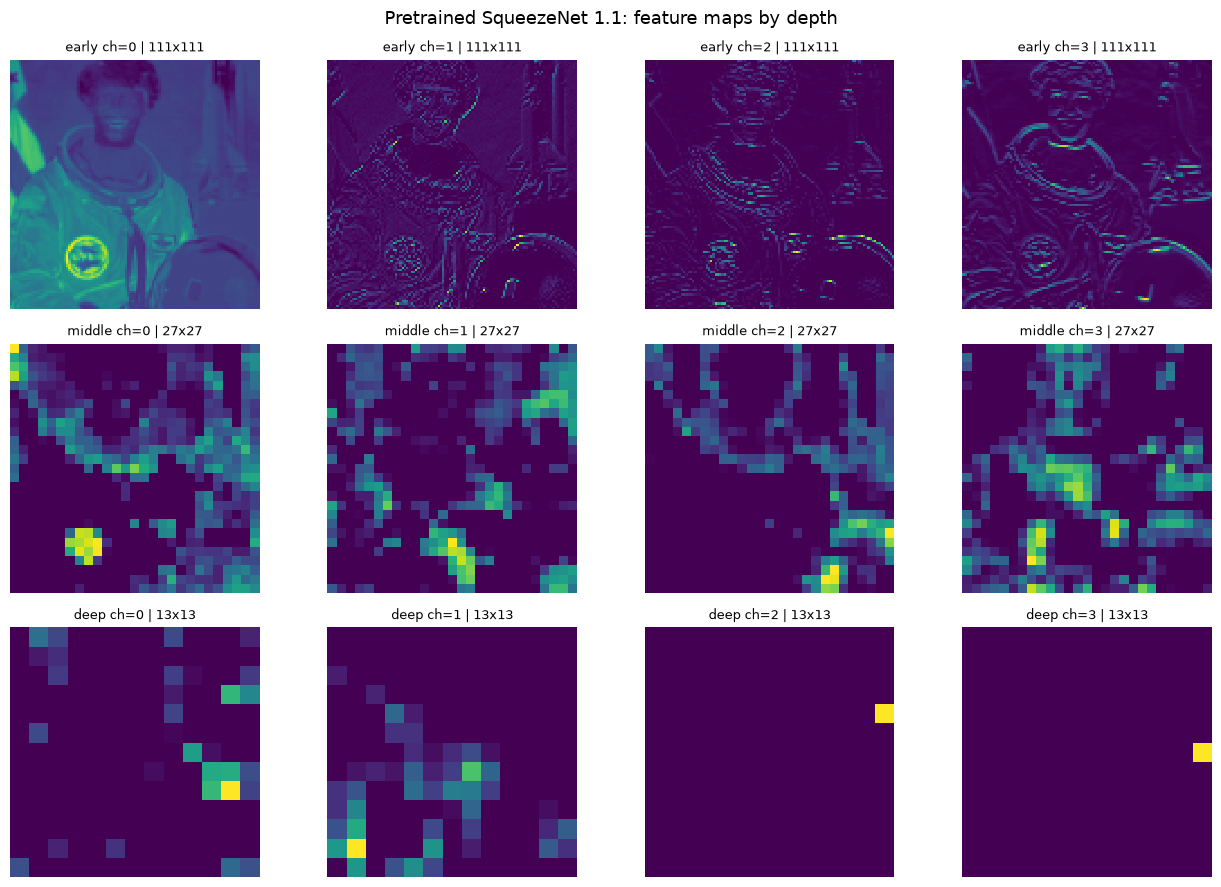

In [7]:
# Forward Hook: 출력 저장 후 반드시 제거 (중복 등록·메모리 누적 방지)
feature_maps = {}

def save_feature(name):
    def hook(module, inputs, output):
        feature_maps[name] = output.detach().cpu().clone()
    return hook

hook_layers = {'early': 1, 'middle': 6, 'deep': 12}
hooks = [
    model.features[idx].register_forward_hook(save_feature(name))
    for name, idx in hook_layers.items()
]
try:
    with torch.inference_mode():
        _ = model(input_tensor)
finally:
    for hook in hooks:
        hook.remove()

expected_shapes = {
    'early': (1, 64, 111, 111),
    'middle': (1, 256, 27, 27),
    'deep': (1, 512, 13, 13),
}
for name, expected in expected_shapes.items():
    actual = tuple(feature_maps[name].shape)
    assert actual == expected, (name, actual, expected)
    print(f'{name:6s}: NCHW {actual} | channels={actual[1]}, spatial={actual[2]}x{actual[3]}')

# 초기/중간/깊은 계층에서 동일한 번호 네 채널만 우선 관찰
layers_to_show = ['early', 'middle', 'deep']
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for i, layer_name in enumerate(layers_to_show):
    fmap = feature_maps[layer_name]
    for j, ch in enumerate([0, 1, 2, 3]):
        show_feature(axes[i, j], fmap, ch, layer_name)
fig.suptitle('Pretrained SqueezeNet 1.1: feature maps by depth', fontsize=13)
plt.tight_layout(); plt.show()

**중간 결과 확인 ⑤**

- 공간 크기: `111×111 → 27×27 → 13×13` (이 모델에서 선택한 계층에 한정된 결과)
- 채널 수: `64 → 256 → 512`
- 계층마다 색상 범위를 개별로 조정했으므로 화면의 '밝기'만으로 활성화 강도를 직접 비교하지 않습니다.
- 13×13 이미지를 화면에 크게 늘려 보여주더라도 실제 데이터 해상도가 커진 것은 아닙니다.

**관찰 질문 C-1:** 계층이 깊어지면서 공간적 해상도와 채널 수가 어떻게 바뀌나요? 이러한 변화가 Receptive Field와 어떻게 연결될까요?

## C-2. ★ 깊은 계층에서 채널 선택 변경 (약 5분)

**★ 변경할 값:** `deep_channels = [0,1,2,3]` → `[8,16,32,64]`. 모델과 입력 이미지는 고정하고 관찰하는 채널만 변경합니다.

깊은 계층 ch=  0 | min=0.0000, max=70.5780, mean=3.4813
깊은 계층 ch=  1 | min=0.0000, max=117.7351, mean=8.3087
깊은 계층 ch=  2 | min=0.0000, max=20.8886, mean=0.1236
깊은 계층 ch=  3 | min=0.0000, max=10.7182, mean=0.0634


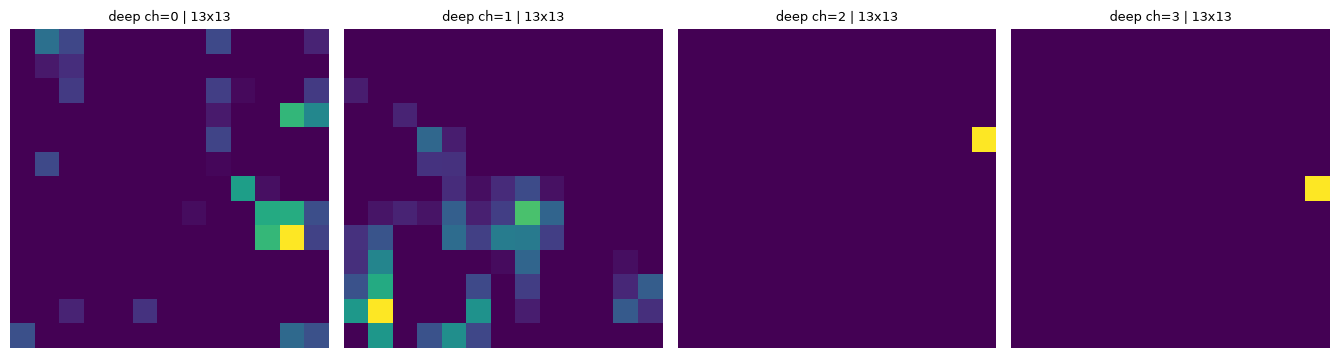

In [8]:
# ★ 변경할 값: [0, 1, 2, 3] → [8, 16, 32, 64]
deep_channels = [0, 1, 2, 3]
deep_map = feature_maps['deep']
assert len(deep_channels) == 4
assert all(0 <= ch < deep_map.shape[1] for ch in deep_channels)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.5))
for ax, ch in zip(axes, deep_channels):
    min_val, max_val, mean_val = show_feature(ax, deep_map, ch, 'deep')
    print(f'깊은 계층 ch={ch:3d} | min={min_val:.4f}, max={max_val:.4f}, mean={mean_val:.4f}')
plt.tight_layout(); plt.show()

**관찰 질문 C-2:** 같은 계층에서도 채널별 반응이 같나요? 특정 채널이 '고양이 귀 검출기'처럼 하나의 의미를 갖는다고 **이번 결과만으로 단정할 수 있을까요?**

## E. 오늘의 세 실습 종합 비교 (5분)

**모델 성능을 비교하는 시간이 아닙니다.** 고정 필터의 *Gradient*와 학습된 CNN의 *Feature Map*, Conv의 *Shape*를 구분해 설명해 봅니다.

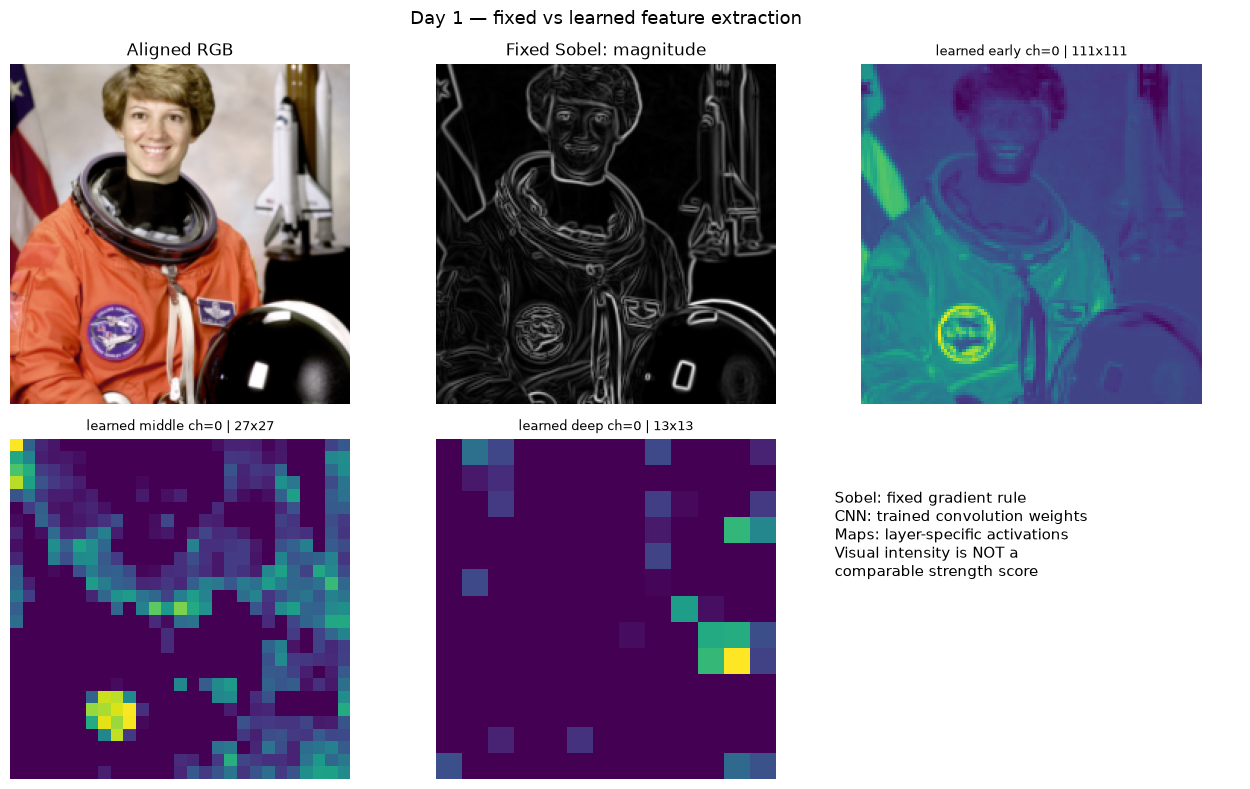

실습 완료 | 고정 Sobel vs 학습 CNN / Conv 출력 Shape / 계층별 Feature Maps


In [9]:
# 종합 시각화: Sobel과 CNN의 서로 다른 출력 표현을 한 화면에서 관찰
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes[0, 0].imshow(aligned_rgb); axes[0, 0].set_title('Aligned RGB')
axes[0, 1].imshow(sobel_mag_view, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title('Fixed Sobel: magnitude')
show_feature(axes[0, 2], feature_maps['early'], 0, 'learned early')
show_feature(axes[1, 0], feature_maps['middle'], 0, 'learned middle')
show_feature(axes[1, 1], feature_maps['deep'], 0, 'learned deep')
axes[1, 2].axis('off')
axes[1, 2].text(0.03, 0.85,
                'Sobel: fixed gradient rule\n'
                'CNN: trained convolution weights\n'
                'Maps: layer-specific activations\n'
                'Visual intensity is NOT a\ncomparable strength score',
                va='top', fontsize=11)
for ax in [axes[0, 0], axes[0, 1]]: ax.axis('off')
fig.suptitle('Day 1 — fixed vs learned feature extraction', fontsize=13)
plt.tight_layout(); plt.show()

print('실습 완료 | 고정 Sobel vs 학습 CNN / Conv 출력 Shape / 계층별 Feature Maps')

### 최종 결과 해석 — 각 문장을 직접 완성하세요

| 핵심 질문 | 내가 확인한 내용 |
|---|---|
| A. Sobel과 CNN 필터의 가장 중요한 차이 | __________ |
| A. 초기 CNN의 서로 다른 채널에서 발견한 차이 | __________ |
| B. Stride·Padding을 바꾸었을 때 Shape와 파라미터 수 | __________ |
| B. Kernel Size를 바꾸었을 때 Shape와 파라미터 수 | __________ |
| C. 초기→중간→깊은 계층의 (C, H, W) 변화 | __________ |
| Feature Map 시각화만으로 확정할 수 없는 정보 | __________ |

**오늘의 핵심 결론**

- Sobel은 사람이 정의한 가중치로 밝기 변화를 계산합니다. CNN은 학습된 필터로 여러 특징맵을 생성합니다.
- 출력 Tensor의 **채널 수**는 출력 Feature Map 개수입니다. **공간 크기**와 **파라미터 수**는 다른 개념입니다.
- CNN은 여러 계층에서 점차 특징 표현을 결합할 수 있지만, Feature Map만으로 특정 채널의 의미를 확정하지는 않습니다.

**다음 시간 (⑧):** 이미지 데이터 → 전처리 → 고정 필터 → 학습 가능한 CNN 필터를 연결하여 Day 1 전체를 정리하겠습니다.